In [1]:
import pandas as pd
import numpy as np
import joblib

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

print("Thư viện đã được import thành công!")

Thư viện đã được import thành công!


In [2]:
import os
import random
import numpy as np
import tensorflow as tf

# Cố định Random Seed
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Yêu cầu TensorFlow sử dụng phép tính xác định
tf.config.experimental.enable_op_determinism()

print("Random Seed đã được cố định:", SEED)

Random Seed đã được cố định: 42


In [3]:
# Đọc dữ liệu đã chuẩn hóa
X_train = pd.read_csv("../data/processed/X_train_scaled.csv")
X_val = pd.read_csv("../data/processed/X_val_scaled.csv")
X_test = pd.read_csv("../data/processed/X_test_scaled.csv")

# Đọc nhãn
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_val = pd.read_csv("../data/processed/y_val.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

# Kiểm tra kích thước dữ liệu
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

print("\nPhân bố nhãn Train:")
print(y_train.value_counts())

X_train: (396332, 79)
X_val: (98194, 79)
X_test: (100117, 79)

y_train: (396332,)
y_val: (98194,)
y_test: (100117,)

Phân bố nhãn Train:
fraud
0    391292
1      5040
Name: count, dtype: int64


In [4]:
# Tính trọng số cho từng lớp
classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, class_weights))

print("Class Weights:")
print(class_weight_dict)

Class Weights:
{np.int64(0): np.float64(0.5064402032241906), np.int64(1): np.float64(39.3186507936508)}


In [5]:
# Xác định số lượng đặc trưng đầu vào
input_dim = X_train.shape[1]

# Xây dựng mô hình ANN
ann_model = Sequential([
    Input(shape=(input_dim,)),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

# Cấu hình mô hình
ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", "Recall", "Precision"]
)

# Hiển thị kiến trúc
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,609 (80.50 KB)

 Trainable params: 20,609 (80.50 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Thiết lập Early Stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Huấn luyện ANN
history = ann_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=256,
    class_weight=class_weight_dict,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
1549/1549 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - Precision: 0.2171 - Recall: 0.9754 - accuracy: 0.9550 - loss: 0.0884 - val_Precision: 0.2824 - val_Recall: 0.9917 - val_accuracy: 0.9722 - val_loss: 0.0546
Epoch 2/50
1549/1549 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - Precision: 0.2562 - Recall: 0.9865 - accuracy: 0.9634 - loss: 0.0611 - val_Precision: 0.3085 - val_Recall: 0.9880 - val_accuracy: 0.9755 - val_loss: 0.0465
Epoch 3/50
1549/1549 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - Precision: 0.2652 - Recall: 0.9873 - accuracy: 0.9651 - loss: 0.0580 - val_Precision: 0.3006 - val_Recall: 0.9880 - val_accuracy: 0.9746 - val_loss: 0.0486
Epoch 4/50
1549/1549 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - Precision: 0.2717 - Recall: 0.9865 - accuracy: 0.9662 - loss: 0.0574 - val_Precision: 0.2804 - val_Recall: 0.9907 - val_accuracy: 0.9719 - val_loss: 0.0520
Epoch 5/50
1549/1549 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - Precision: 0.2806 - Recall: 0.9869 - accuracy: 0.9677 - loss: 0.0567 - val_Precision: 0.2902 - v

In [7]:
# Tìm Epoch có Validation Loss thấp nhất
best_epoch = np.argmin(history.history["val_loss"]) + 1
best_val_loss = np.min(history.history["val_loss"])

print("Epoch tốt nhất:", best_epoch)
print("Validation Loss tốt nhất:", best_val_loss)
print("Tổng số Epoch đã chạy:", len(history.history["loss"]))

Epoch tốt nhất: 2
Validation Loss tốt nhất: 0.046518489718437195
Tổng số Epoch đã chạy: 7


In [8]:
# Dự đoán xác suất gian lận
val_probs = ann_model.predict(X_val, verbose=0).flatten()

print("5 xác suất đầu tiên:")
print(val_probs[:5])

print("\nXác suất nhỏ nhất:", val_probs.min())
print("Xác suất lớn nhất:", val_probs.max())
print("Xác suất trung bình:", val_probs.mean())

5 xác suất đầu tiên:
[3.9444207e-05 3.5632966e-05 4.4875203e-05 2.1382235e-03 8.1314291e-05]

Xác suất nhỏ nhất: 2.149653e-07
Xác suất lớn nhất: 0.99999917
Xác suất trung bình: 0.03238751


In [9]:
from sklearn.metrics import precision_recall_curve
import numpy as np

# Tính Precision và Recall trên Validation
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_probs
)

# Tính F1-score
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Tìm ngưỡng có F1-score cao nhất
best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]

print("Ngưỡng tối ưu:", best_threshold)
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])
print("F1-score:", f1_scores[best_idx])

Ngưỡng tối ưu: 0.97361743
Precision: 0.8204667863554758
Recall: 0.8462962962962963
F1-score: 0.8331814037786355


Threshold: 0.97361743
Precision: 0.7871244635193133
Recall: 0.8490740740740741
F1-score: 0.8169265033407572
PR-AUC: 0.9118138805443139


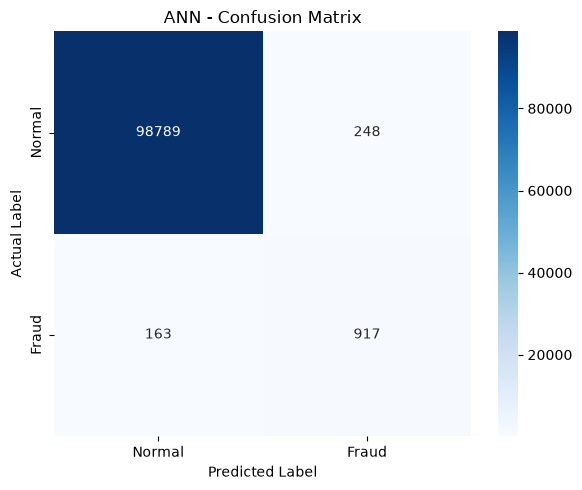


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     99037
           1       0.79      0.85      0.82      1080

    accuracy                           1.00    100117
   macro avg       0.89      0.92      0.91    100117
weighted avg       1.00      1.00      1.00    100117



In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Dự đoán xác suất trên tập Test
test_probs = ann_model.predict(X_test, verbose=0).flatten()

# Sử dụng ngưỡng đã chọn từ Validation
y_test_pred = (test_probs >= best_threshold).astype(int)

# Đánh giá mô hình
print("Threshold:", best_threshold)
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-score:", f1_score(y_test, y_test_pred))
print("PR-AUC:", average_precision_score(y_test, test_probs))

# CONFUSION MATRIX

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("ANN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

In [11]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Dự đoán xác suất trên tập Test
test_probs = ann_model.predict(X_test, verbose=0).flatten()

# Phân loại theo ngưỡng đã chọn trên Validation
y_test_pred = (test_probs >= best_threshold).astype(int)

# Tổng hợp các chỉ số đánh giá
evaluation_results = pd.DataFrame({
    "Chỉ số đánh giá": [
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Giá trị": [
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0),
        roc_auc_score(y_test, test_probs),
        average_precision_score(y_test, test_probs)
    ]
})

# Đánh số thứ tự từ 1
evaluation_results.index = range(1, len(evaluation_results) + 1)

# Hiển thị kết quả
print("Kết quả đánh giá mô hình ANN")

display(
    evaluation_results.style
    .format({"Giá trị": "{:.5f}"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "center")]},
        {"selector": "td", "props": [("text-align", "center")]}
    ])
)

Kết quả đánh giá mô hình ANN


,Chỉ số đánh giá,Giá trị
1,Precision,0.78712
2,Recall,0.84907
3,F1-Score,0.81693
4,ROC-AUC,0.99851
5,PR-AUC,0.91181


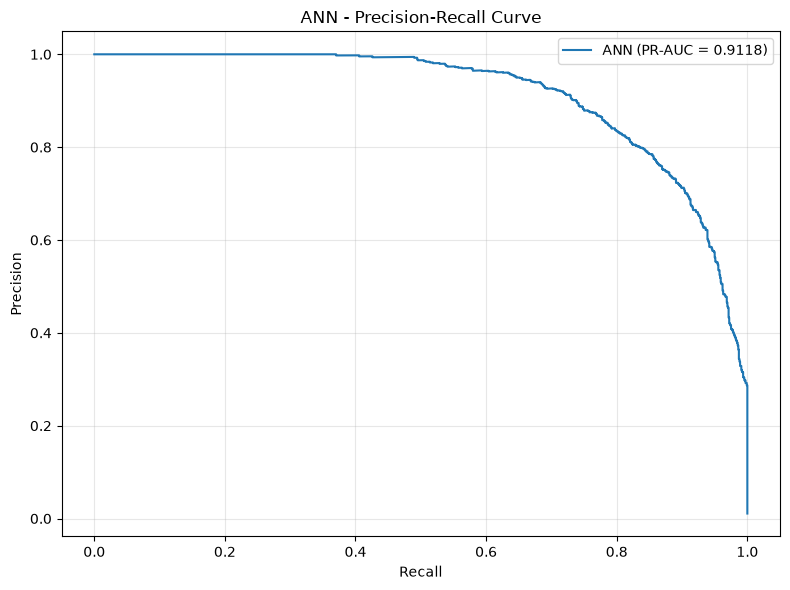

In [12]:
# PRECISION-RECALL CURVE

from sklearn.metrics import precision_recall_curve

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    test_probs
)

pr_auc = average_precision_score(y_test, test_probs)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"ANN (PR-AUC = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("ANN - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
print("Tổng số Epoch đã chạy:", len(history.history["loss"]))

Tổng số Epoch đã chạy: 7


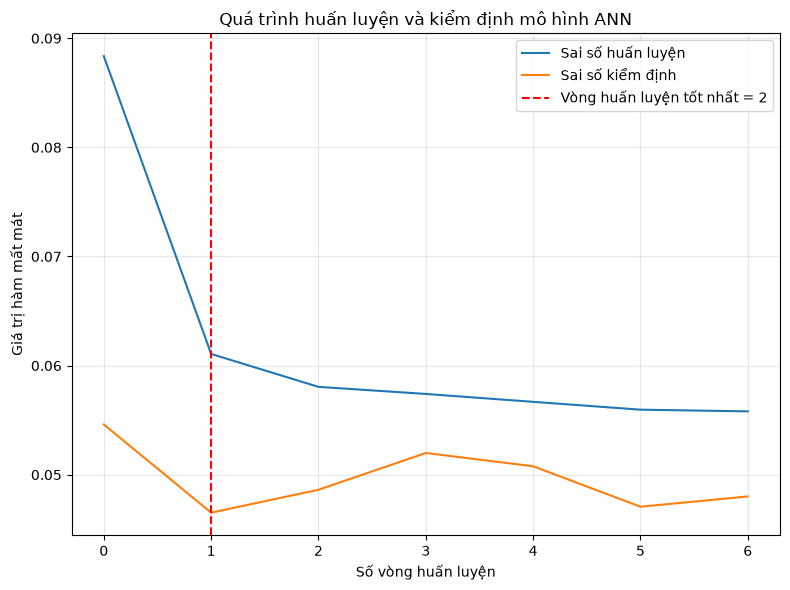

In [14]:
# Biểu đồ hàm mất mát trong quá trình huấn luyện ANN

plt.figure(figsize=(8, 6))

plt.plot(
    history.history["loss"],
    label="Sai số huấn luyện"
)

plt.plot(
    history.history["val_loss"],
    label="Sai số kiểm định"
)

plt.axvline(
    best_epoch - 1,
    color="red",
    linestyle="--",
    label=f"Vòng huấn luyện tốt nhất = {best_epoch}"
)

plt.xlabel("Số vòng huấn luyện")
plt.ylabel("Giá trị hàm mất mát")
plt.title("Quá trình huấn luyện và kiểm định mô hình ANN")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

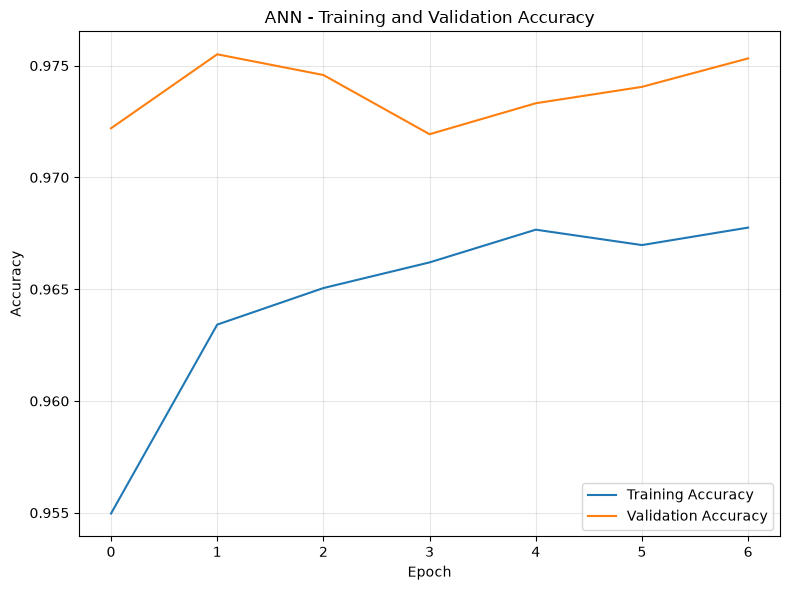

In [15]:
# TRAINING AND VALIDATION ACCURACY

plt.figure(figsize=(8, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN - Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
# Lưu mô hình ANN
ann_model.save("../models/ann.keras")

# Lưu threshold đã chọn từ Validation
with open("../models/ann_threshold.txt", "w") as f:
    f.write(str(best_threshold))

print("Đã lưu ANN và threshold thành công!")

Đã lưu ANN và threshold thành công!
